In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Jupyter is working!")
print("Pandas:", pd.__version__)

Jupyter is working!
Pandas: 3.1.1


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All imports successful!")

All imports successful!


In [4]:
import os

print(os.getcwd())
print(os.listdir())


print(os.listdir("../results/FINALIZED_RESULTS/analysis"))


c:\Users\Aneesh Anand\csresearch2\CS-Research-II-Fall-26\visualizations
['heatmaps.ipynb']
['check.csv', 'check_sessions.csv', 'main.csv', 'main_sessions.csv']


In [5]:
main_df = pd.read_csv("../results/FINALIZED_RESULTS/analysis/main.csv")

print("Shape:", main_df.shape)
print("\nColumns:")
print(main_df.columns.tolist())

main_df.head()

Shape: (6600, 51)

Columns:
['session_id', 'model', 'effort', 'provider', 'tally_variant', 'task_id', 'run_index', 'check', 'check_name', 'group', 'case_type', 'owner', 'rebuilt', 'pair_id', 'variant', 'pair_changes', 'weak_pair', 'chance', 'candidate_answers', 'correct_answers', 'n_rules', 'prompt_words', 'transcript_courses', 'expected_min', 'expected_max', 'outcome', 'semantic_ok', 'error_type', 'tier1_ok', 'tier2_ok', 'tier3_ok', 'tier4_ok', 'sections_registered', 'registered_nothing', 'pair_passed', 'same_answer_as_twin', 'prompt_tokens', 'cached_tokens', 'cache_write_tokens', 'completion_tokens', 'reasoning_tokens', 'reasoning_chars', 'usd_cost', 'first_token_ms', 'latency_ms', 'finish_reason', 'model_version', 'service_tier', 'attempts', 'generation_time_ms', 'reused']


,session_id,model,effort,provider,tally_variant,task_id,run_index,check,check_name,group,...,reasoning_chars,usd_cost,first_token_ms,latency_ms,finish_reason,model_version,service_tier,attempts,generation_time_ms,reused
0,compact-20261105T221641Z-low,google/gemini-4-argon,low,google-ai-studio/flex,compact,T1-001,0,T1,Time-of-day words (morning / afternoon),Temporal reasoning,...,NaN,0.301210,11037.4575,12880.9774,stop,google/gemini-4-argon-20261013,flex,1.0,12384.0,NaN
1,compact-20261105T221641Z-low,google/gemini-4-argon,low,google-ai-studio/flex,compact,T1-002,0,T1,Time-of-day words (morning / afternoon),Temporal reasoning,...,NaN,0.017986,4672.0247,6271.7808,stop,google/gemini-4-argon-20261013,flex,1.0,5814.0,NaN
2,compact-20261105T221641Z-low,google/gemini-4-argon,low,google-ai-studio/flex,compact,T1-003,0,T1,Time-of-day words (morning / afternoon),Temporal reasoning,...,NaN,0.019872,5999.8731,7718.3739,stop,google/gemini-4-argon-20261013,flex,1.0,7306.0,NaN
3,compact-20261105T221641Z-low,google/gemini-4-argon,low,google-ai-studio/flex,compact,T1-004,0,T1,Time-of-day words (morning / afternoon),Temporal reasoning,...,NaN,0.017964,11466.1014,13327.9209,stop,google/gemini-4-argon-20261013,flex,1.0,12895.0,NaN
4,compact-20261105T221641Z-low,google/gemini-4-argon,low,google-ai-studio/flex,compact,T1-005,0,T1,Time-of-day words (morning / afternoon),Temporal reasoning,...,NaN,0.020111,4929.0671,6652.2845,stop,google/gemini-4-argon-20261013,flex,1.0,6189.0,NaN


In [6]:
print("Models:")
print(main_df["model"].nunique())

print("\nEffort levels:")
print(main_df["effort"].value_counts())

print("\nTest groups:")
print(main_df["group"].value_counts())

print("\nOutcomes:")
print(main_df["outcome"].value_counts())

print("\nCheck categories:")
print(main_df["check"].value_counts(dropna=False))

Models:
11

Effort levels:
effort
low       2200
medium    2200
high      2200
Name: count, dtype: int64

Test groups:
group
Student record                 1716
Temporal reasoning             1320
Request constraints            1056
Course and section identity     792
Capacity                        660
Days                            528
Completeness of the answer      528
Name: count, dtype: int64

Outcomes:
outcome
semantic_ok          4429
consistency_error     891
semantic_error        734
schema_error          284
syntactic_error       249
generation_failed      13
Name: count, dtype: int64

Check categories:
check
T1     198
T2     198
D1     198
D2     198
C1     198
C2     198
I1     198
I2     198
K1     198
K3     198
R1     198
R2     198
O1     198
O2     198
T3     132
T4     132
T5     132
T6     132
T7     132
T8     132
T9     132
D3     132
C3     132
C4     132
I3     132
I4     132
I5     132
K4     132
K5     132
K6     132
K7     132
K8     132
R3     132
R4     1

In [7]:
print("Complete outcome distribution:")
print(main_df["outcome"].value_counts().to_string())

print("\nError type distribution:")
print(main_df["error_type"].value_counts().head(20).to_string())

print("\nNumber of unique error types:")
print(main_df["error_type"].nunique())

print("\nGeneration failures:")
print((main_df["outcome"] == "generation_failed").sum())

Complete outcome distribution:
outcome
semantic_ok          4429
consistency_error     891
semantic_error        734
schema_error          284
syntactic_error       249
generation_failed      13

Error type distribution:
error_type
section_details_miscopied        394
malformed_section_entry          284
invalid_waitlist                 247
not_json                         170
two_sections_of_one_course       158
meeting_days_ignored             137
truncated_at_max_tokens           79
campus_ignored                    61
ambiguity_misread                 61
full_section                      56
constraint_dropped                51
open_seat_arithmetic              46
wrong_number_of_sections          33
valid_answer_rejected             32
negation_ignored                  31
noon_misread                      30
preference_priority_misread       29
satisfied_requirement_ignored     27
time_limit_ignored                25
prerequisite_missing              23

Number of unique error type

In [8]:
# Exclude provider/generation failures
valid_df = main_df[main_df["outcome"] != "generation_failed"].copy()

# Keep rows that actually have an error
errors_df = valid_df[valid_df["error_type"].notna()].copy()

# Find the 10 most common error types
top_errors = errors_df["error_type"].value_counts().head(10).index.tolist()

print("Valid calls:", len(valid_df))
print("Error calls:", len(errors_df))
print("\nTop 10 error types:")
print(top_errors)

Valid calls: 6587
Error calls: 2158

Top 10 error types:
['section_details_miscopied', 'malformed_section_entry', 'invalid_waitlist', 'not_json', 'two_sections_of_one_course', 'meeting_days_ignored', 'truncated_at_max_tokens', 'campus_ignored', 'ambiguity_misread', 'full_section']


In [ ]:
# Create shorter model names for the chart labels
valid_df["model_label"] = (
    valid_df["model"]
    .str.split("/")
    .str[-1]
    .str.replace(":free", "", regex=False)
)       #Creates a new column "model_label" in the valid_df DataFrame by extracting the last part of the "model" column (after splitting by "/") and removing ":free" from the string. This is likely done to create shorter, more readable model names for visualization or analysis purposes.

errors_df["model_label"] = (
    errors_df["model"]
    .str.split("/")
    .str[-1]
    .str.replace(":free", "", regex=False)
)          #Creates a new column "model_label" in the errors_df DataFrame by extracting the last part of the "model" column (after splitting by "/") and removing ":free" from the string. This is likely done to create shorter, more readable model names for visualization or analysis purposes. 
 

# Count each error type within each category
# Divide by the total valid calls in that category
def calculate_error_rates(category):
    counts = pd.crosstab(
        errors_df[category],
        errors_df["error_type"]                     #Counts how many times each error type occurs within each category.
    )

    totals = valid_df.groupby(category).size()     #Counts the total number of valid calls in each category.

    # Include categories even if they have zero errors
    counts = counts.reindex(
        index=totals.index,
        columns=top_errors,
        fill_value=0
    )   #Makes sure all categories and the same top 10 error types are included, filling missing combinations with zero.

    error_rates = counts.div(totals, axis=0)     #divides the counts of each error type by the total number of valid calls in that category to get the percentage of each error type within that category.

    return error_rates      #returns a DataFrame containing the percentage of each error type within each category, with categories as rows and error types as columns.

print("Data preparation complete!")

Data preparation complete!


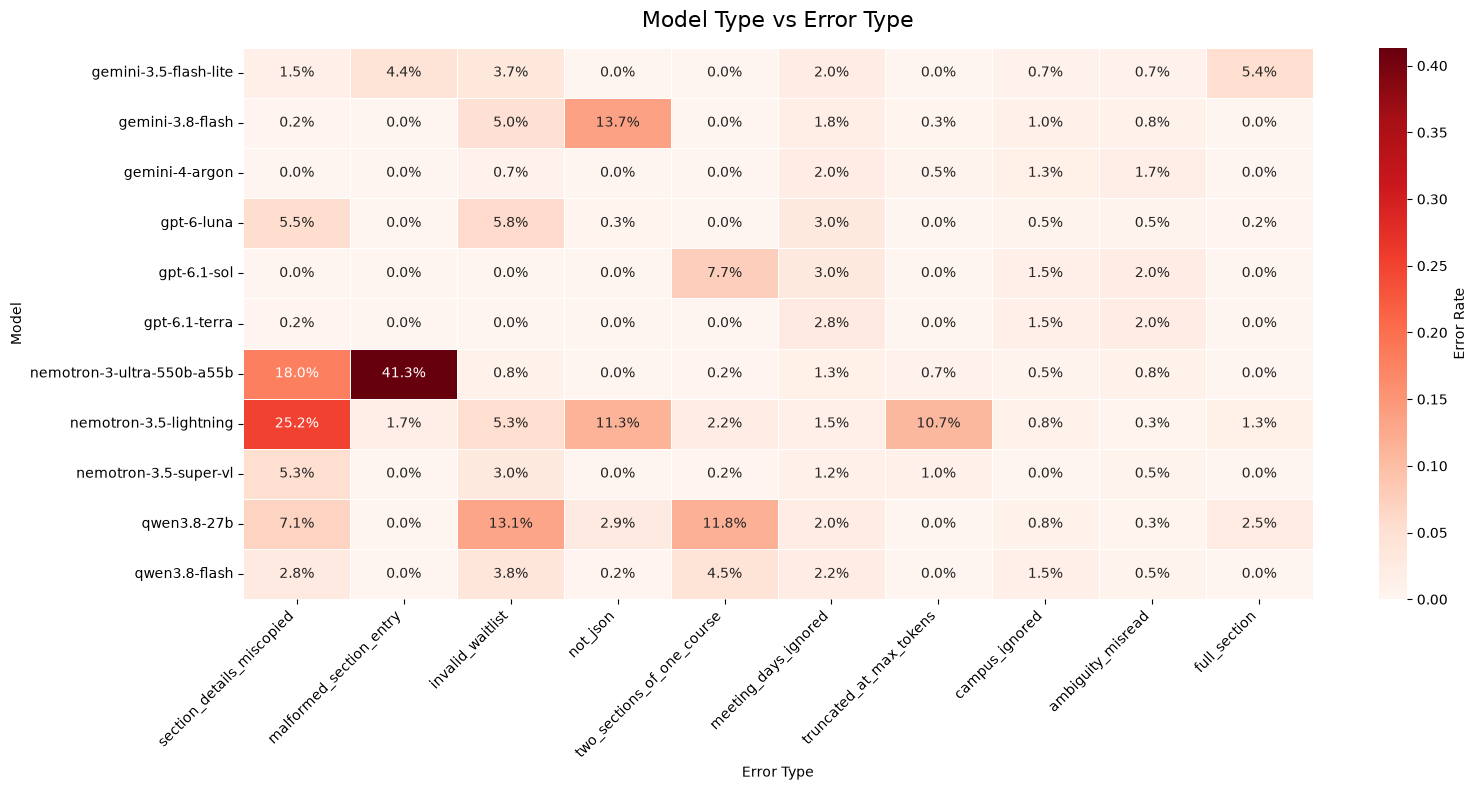

In [ ]:
# Calculate error rates for each model
model_rates = calculate_error_rates("model_label")

# Create the heatmap
plt.figure(figsize=(16, 8))  

sns.heatmap(
    model_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Model Type vs Error Type", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Model Type vs Top 10 Error Types

Purpose of the Heatmap

This heatmap compares the error patterns of 11 different language models across the 10 most frequently occurring error types in the evaluation experiments.

Its purpose is to identify which types of errors occur more frequently for different models and determine whether certain models struggle with particular aspects of transaction-related tasks.

How to Read the Heatmap

Rows: Each row represents a different language model.

Columns: Each column represents one of the 10 most common error types found across the evaluation results.

Cells: Each cell displays the percentage of valid evaluation calls for that model that resulted in the corresponding error.

Color intensity: Darker red indicates a higher error rate, while lighter red indicates a lower error rate.

The percentages allow us to compare how frequently each model produces a particular error relative to its total number of valid evaluation calls.

What the Error Types Represent

The heatmap includes several different categories of mistakes:

section_details_miscopied: Incorrectly copying or reproducing details about a course section.

malformed_section_entry: Producing a section entry that does not follow the required structure.

invalid_waitlist: Incorrectly handling or generating waitlist information.

not_json: Producing an output that is not valid JSON.

two_sections_of_one_course: Selecting or including two sections of the same course when this is not permitted.

meeting_days_ignored: Failing to follow or account for requested meeting days.

truncated_at_max_tokens: Producing an incomplete response because the generation reached its token limit.

campus_ignored: Failing to respect the requested campus.

ambiguity_misread: Misinterpreting an ambiguous request or instruction.

full_section: Incorrectly handling a course section that has reached capacity.

What This Heatmap Helps Reveal

The visualization helps identify differences in how models handle transaction-related requirements.

For example:

A model with a darker cell under not_json may have more difficulty consistently producing correctly structured responses.

A darker cell under meeting_days_ignored may indicate difficulty following scheduling constraints.

A darker cell under section_details_miscopied may suggest problems accurately preserving course and section information.

Similar dark patterns across several models may indicate that certain tasks are challenging for language models in general.

Different patterns across models may suggest that models have different strengths and weaknesses.

The heatmap therefore provides a way to compare not only how often models make mistakes, but also what kinds of mistakes they tend to make.

Important Observations When Interpreting Results

A darker cell indicates a higher error rate for that specific error type, not necessarily worse overall model performance.

The heatmap should be interpreted by comparing patterns across both rows and columns:

Comparing across a row shows which error types are more common for a particular model.

Comparing down a column shows which models have higher error rates for a particular error type.

The heatmap includes the 10 most frequent error types across the entire dataset. Other less frequent errors are not displayed.

The results are also aggregated across all three effort levels (Low, Medium, and High) and all seven test groups. Therefore, this visualization does not isolate the effect of effort level or individual test categories.

Overall Takeaway

This heatmap provides a model-by-model comparison of the most common error patterns observed during the transaction evaluation experiments.

It helps identify recurring weaknesses, differences in model behavior, and specific areas where models may struggle with structured output, course and section information, scheduling requirements, and transaction constraints.

Rather than treating every incorrect response as the same type of failure, the visualization breaks errors into individual categories, providing a more detailed understanding of model reliability and behavior.

In [11]:
group_rates = calculate_error_rates("group")

print(group_rates)

error_type                   section_details_miscopied  \
group                                                    
Capacity                                      0.085366   
Completeness of the answer                    0.039773   
Course and section identity                   0.053030   
Days                                          0.055028   
Request constraints                           0.046490   
Student record                                0.077193   
Temporal reasoning                            0.049242   

error_type                   malformed_section_entry  invalid_waitlist  \
group                                                                    
Capacity                                    0.035061          0.004573   
Completeness of the answer                  0.049242          0.068182   
Course and section identity                 0.051768          0.061869   
Days                                        0.032258          0.039848   
Request constraints              

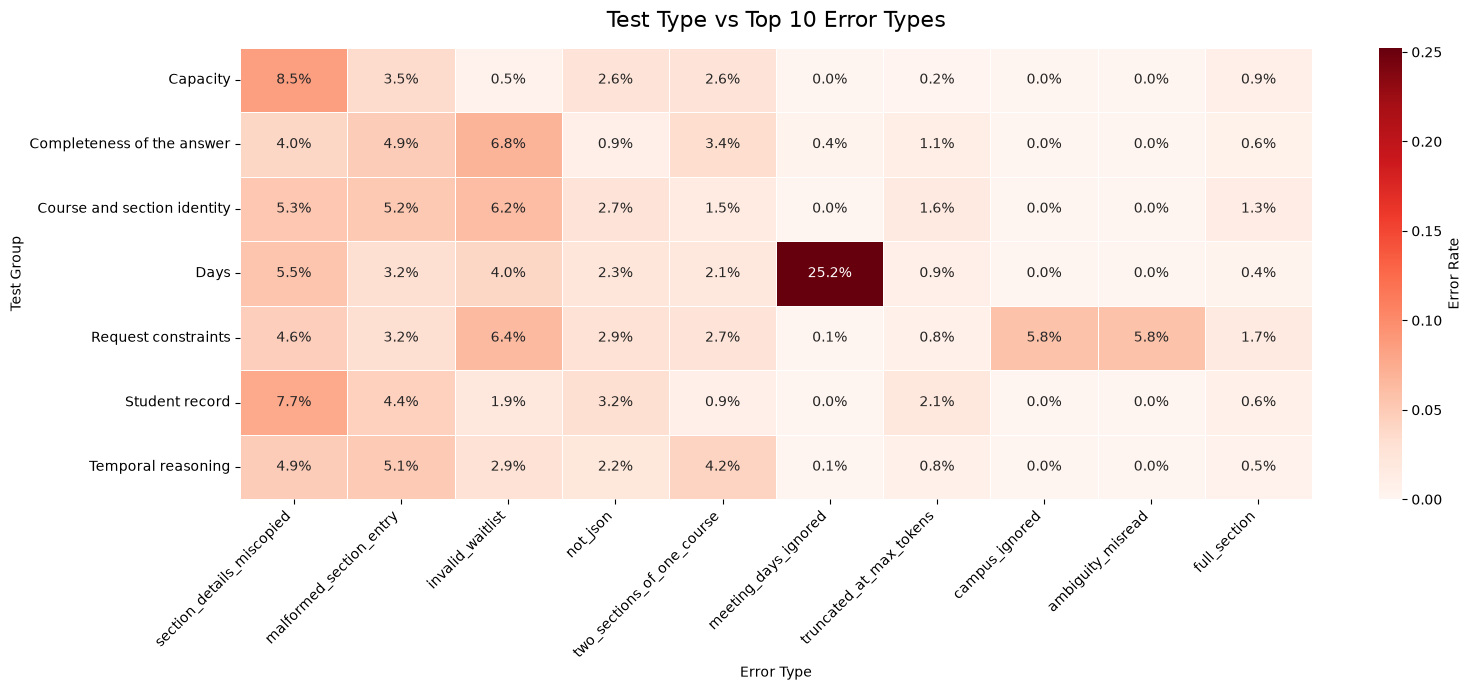

In [12]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    group_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Test Type vs Top 10 Error Types", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Test Group")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Test Type vs Top 10 Error Types Heatmap

Purpose of the Heatmap

This heatmap compares seven different test groups against the 10 most frequently occurring error types in the evaluation experiments.

The purpose of this visualization is to identify which categories of evaluation tasks are associated with particular errors and determine whether certain types of tasks are more challenging for the language models.

Rather than comparing individual models, this heatmap focuses on the types of tasks being evaluated.

How to Read the Heatmap

Rows: Each row represents one of the seven test groups.

Columns: Each column represents one of the 10 most frequently occurring error types.

Cells: Each cell displays the percentage of valid evaluation calls within that test group that resulted in the corresponding error.

Color intensity: Darker red indicates a higher error rate, while lighter red indicates a lower error rate.

The percentages allow us to compare how frequently particular errors occur within each test group.

Understanding the Seven Test Groups

The heatmap includes the following seven test groups:

Student record: Evaluates whether the model correctly handles student information and existing course registrations.

Temporal reasoning: Evaluates whether the model understands time-related requirements and scheduling logic.

Request constraints: Evaluates whether the model follows the specific instructions and restrictions provided in a user's request.

Course and section identity: Evaluates whether the model correctly identifies courses and their specific sections.

Capacity: Evaluates whether the model correctly handles course capacity, available seats, and full sections.

Days: Evaluates whether the model correctly follows requested meeting days.

Completeness of the answer: Evaluates whether the model provides a complete response without leaving out required information.

What This Heatmap Helps Reveal

The visualization helps identify which types of evaluation tasks are more frequently associated with particular errors.

For example:

A darker cell under invalid_waitlist for the Capacity group may indicate difficulty handling waitlist-related requirements.

A darker cell under meeting_days_ignored for the Days group may indicate difficulty following requested meeting-day constraints.

A darker cell under section_details_miscopied for Course and section identity may suggest problems accurately preserving course and section information.

A darker cell under not_json across several test groups may suggest that structured output errors occur across different types of tasks.

Similar patterns across multiple groups may indicate that certain errors are not limited to one specific category of evaluation.

These comparisons help identify the types of tasks that may present greater challenges during transaction processing.

Why Error Rates Are Used Instead of Raw Error Counts

The heatmap uses error rates rather than raw error counts because the seven test groups contain different numbers of evaluation calls.

For example, the Student record group contains 1,716 calls, while the Days group contains 528 calls.

Comparing raw error counts could be misleading because a group with more evaluation calls has more opportunities to produce errors.

Error rates account for the total number of valid calls within each group, making comparisons between test groups more meaningful.

In this visualization, error types identify the specific mistakes being measured, while error rates show how frequently those mistakes occur within each test group.

Important Observations When Interpreting Results

The heatmap should be interpreted by comparing patterns across both rows and columns:

Comparing across a row shows which error types occur more frequently within a particular test group.

Comparing down a column shows which test groups have higher rates for a particular error type.

A darker cell indicates a higher error rate for that particular combination of test group and error type. It does not automatically mean that the entire test group performs poorly.

The heatmap includes only the 10 most frequently occurring error types across the entire dataset. The remaining 41 error types are not displayed.

Additionally, the results are aggregated across all 11 language models and all three effort levels (Low, Medium, and High). Therefore, this visualization does not isolate the performance of individual models or effort levels.

Overall Takeaway

The Test Type vs Top 10 Error Types heatmap provides a comparison of the most common error patterns across seven different categories of evaluation tasks.

It helps identify which types of tasks are associated with particular mistakes and whether certain errors appear more frequently in specific evaluation categories.

By examining these patterns, we can better understand the challenges language models encounter when handling student records, scheduling requirements, course and section information, capacity restrictions, and other transaction-related constraints.

This visualization complements the Model Type vs Top 10 Error Types heatmap by shifting the focus from differences between models to differences between the tasks being evaluated.

In [13]:
effort_rates = calculate_error_rates("effort")

# Keep effort levels in the correct order
effort_rates = effort_rates.reindex(["low", "medium", "high"])

print(effort_rates)

error_type  section_details_miscopied  malformed_section_entry  \
effort                                                           
low                          0.060937                 0.047749   
medium                       0.058824                 0.036024   
high                         0.059681                 0.045558   

error_type  invalid_waitlist  not_json  two_sections_of_one_course  \
effort                                                               
low                 0.044111  0.030014                    0.025011   
medium              0.035112  0.021888                    0.017328   
high                0.033257  0.025513                    0.029613   

error_type  meeting_days_ignored  truncated_at_max_tokens  campus_ignored  \
effort                                                                      
low                     0.022283                 0.012278        0.009095   
medium                  0.021888                 0.011400        0.009120   
high      

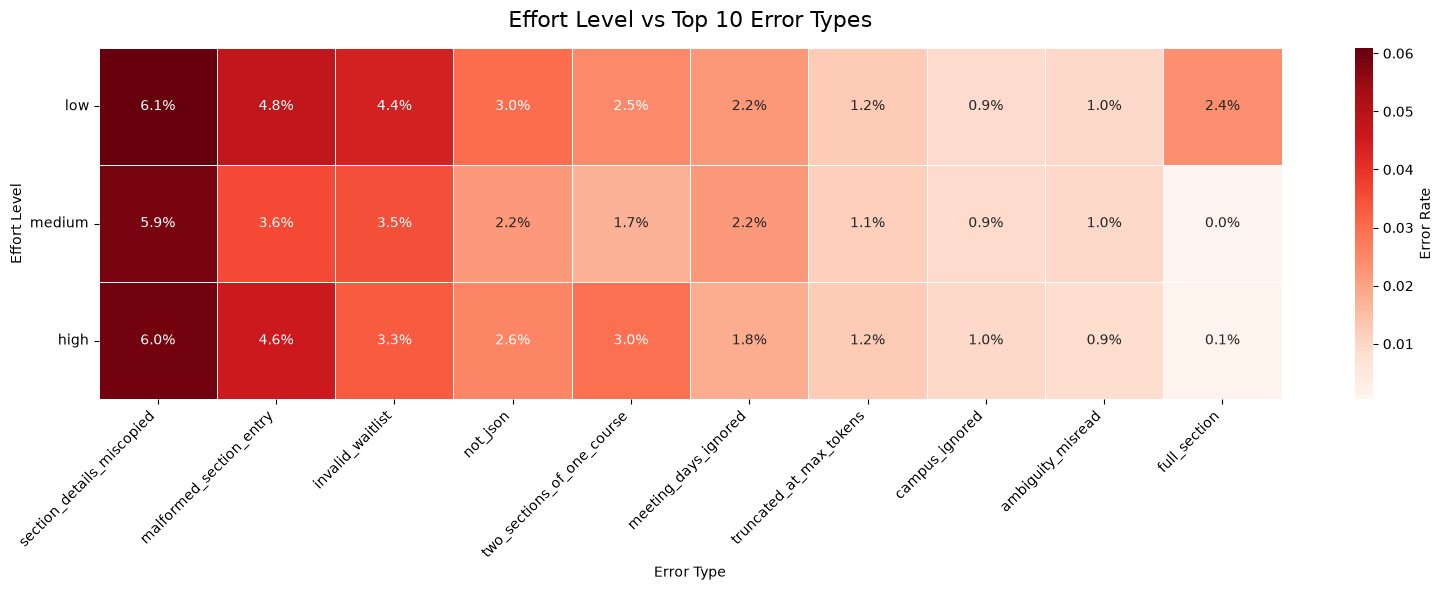

In [14]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    effort_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Effort Level vs Top 10 Error Types", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Effort Level")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Effort Level vs Top 10 Error Types Heatmap

## Purpose of the Heatmap

This heatmap compares three different reasoning effort levels (Low, Medium, and High) against the 10 most frequently occurring error types in the evaluation experiments.

The purpose of this visualization is to investigate whether the amount of reasoning effort used by a language model is associated with differences in error rates.

It helps us understand whether increasing reasoning effort corresponds to fewer errors, whether certain errors are more difficult to avoid, and whether different effort levels produce different error patterns.

## How to Read the Heatmap

- **Rows:** Each row represents one of the three reasoning effort levels: Low, Medium, and High.
- **Columns:** Each column represents one of the 10 most frequently occurring error types.
- **Cells:** Each cell displays the percentage of valid evaluation calls at that effort level that resulted in the corresponding error.
- **Color intensity:** Darker red indicates a higher error rate, while lighter red indicates a lower error rate.

The percentages allow us to compare how frequently particular errors occur at different reasoning effort levels.

## Understanding the Three Effort Levels

The heatmap includes three effort levels:

1. **Low:** Represents evaluations conducted using a low reasoning effort setting.
2. **Medium:** Represents evaluations conducted using a medium reasoning effort setting.
3. **High:** Represents evaluations conducted using a high reasoning effort setting.

These levels allow us to examine whether changing the reasoning effort setting is associated with changes in the types and frequency of errors produced by the models.

## What This Heatmap Helps Reveal

The visualization helps identify relationships between reasoning effort and error patterns.

For example:

- If the Low effort row has a darker cell than the High effort row under `not_json`, this suggests that invalid JSON errors occur more frequently at Low effort.
- If the High effort row has a lighter cell under `meeting_days_ignored`, this may indicate that higher reasoning effort is associated with better handling of scheduling requirements.
- If an error has similar percentages across all three rows, changing reasoning effort may have little effect on that particular error.
- If some errors decrease while others increase, higher reasoning effort may help with certain tasks without improving every aspect of performance.

These comparisons help us investigate whether additional reasoning effort is associated with improvements in transaction correctness.

## Why Error Rates Are Used Instead of Raw Error Counts

The heatmap uses error rates rather than raw error counts because each effort level should be compared relative to its total number of valid evaluation calls.

Each effort level originally contains 2,200 evaluation calls. After excluding generation failures, the number of valid calls may differ slightly.

Comparing raw error counts alone could be misleading because it does not account for the total number of valid calls.

Error rates account for these differences and make comparisons between Low, Medium, and High effort more meaningful.

In this visualization, error types identify the specific mistakes being measured, while error rates show how frequently those mistakes occur at each effort level.

## Important Observations When Interpreting Results

The heatmap should be interpreted by comparing patterns across both rows and columns:

- Comparing across a row shows which error types occur more frequently at a particular effort level.
- Comparing down a column shows how the rate of a particular error changes between Low, Medium, and High effort.

A darker cell indicates a higher error rate for that specific combination of effort level and error type. It does not automatically mean that the entire effort level performs worse.

The heatmap includes only the 10 most frequently occurring error types across the entire dataset. The remaining 41 error types are not displayed.

Additionally, the results are aggregated across all 11 language models and all seven0

In [15]:
# Get all 51 error types
all_errors = errors_df["error_type"].value_counts().index.tolist()

# Create a crosstab using all error types
all_counts = pd.crosstab(
    errors_df["model_label"],
    errors_df["error_type"]
)

# Include all models and all 51 error types
all_counts = all_counts.reindex(
    index=valid_df["model_label"].unique(),
    columns=all_errors,
    fill_value=0
)

# Calculate error rates
all_model_rates = all_counts.div(
    valid_df.groupby("model_label").size(),
    axis=0
)

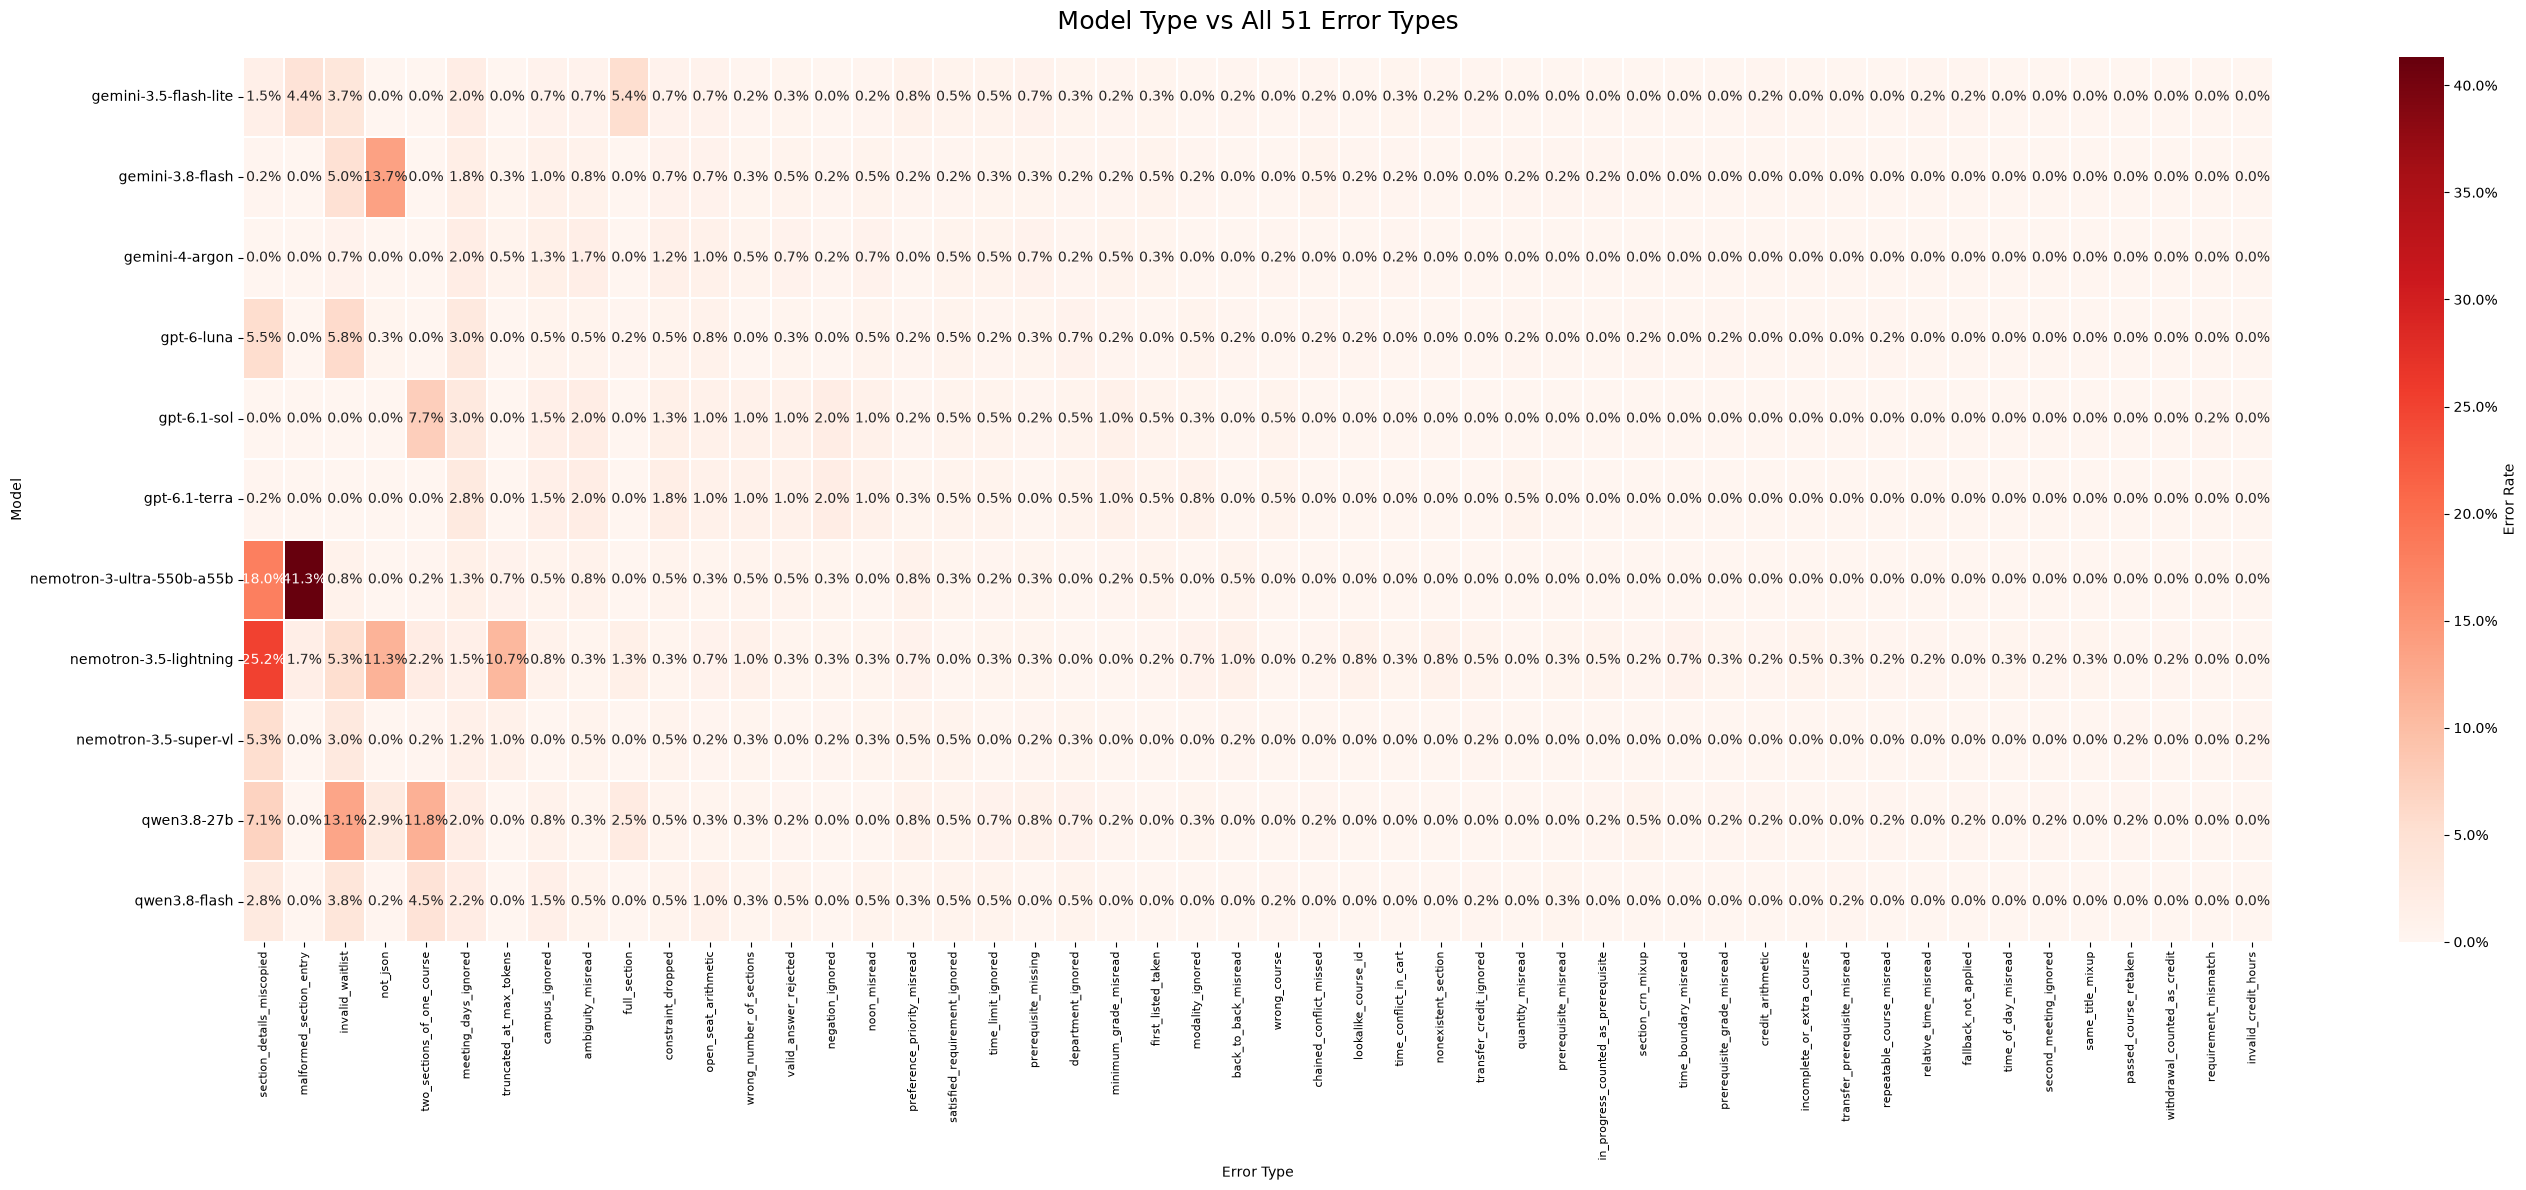

In [16]:
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(28, 12))

sns.heatmap(
    all_model_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.3,
    cbar_kws={
        "label": "Error Rate",
        "format": PercentFormatter(1)
    }
)

plt.title("Model Type vs All 51 Error Types", fontsize=18, pad=20)
plt.xlabel("Error Type")
plt.ylabel("Model")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def calculate_error_distribution(category):

    counts = pd.crosstab(
        errors_df[category],
        errors_df["error_type"]   #Counts how many times each error type occurs within each category.
    )

    totals = errors_df.groupby(category).size()           # Counts the total number of recorded errors in each category.

    counts = counts.reindex(
        index=totals.index,
        columns=top_errors,
        fill_value=0
    )                      #Makes sure all categories and the same top 10 error types are included, filling missing combinations with zero.

    error_percentages = counts.div(totals, axis=0)           # Divides each error type count by the total recorded errors in that category.

    return error_percentages         #returns a DataFrame containing the percentage of each error type within each category, with categories as rows and error types as columns.

In [25]:
print(main_df["effort"].value_counts())

effort
low       2200
medium    2200
high      2200
Name: count, dtype: int64


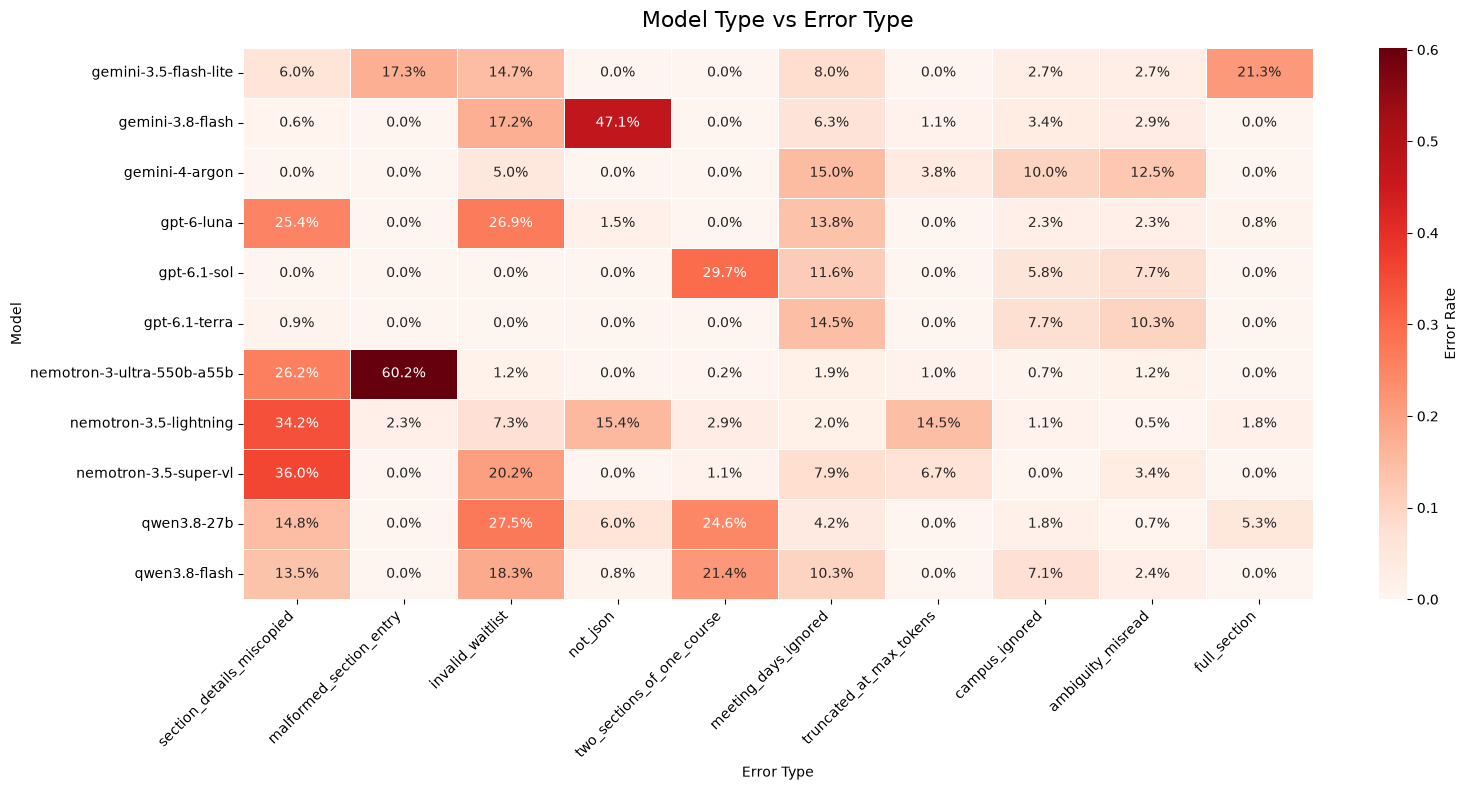

In [26]:
model_rates = calculate_error_distribution("model_label")

# Create the heatmap
plt.figure(figsize=(16, 8))

sns.heatmap(
    model_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Model Type vs Error Type", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Model Type vs Top 10 Error Types Heatmap (Percentage of Errors)

## Purpose of the Heatmap

This heatmap compares the 11 language models against the 10 most frequently occurring error types in the evaluation experiments.

The purpose of this visualization is to investigate how the distribution of errors differs across the language models.

It helps us understand which specific errors make up a larger proportion of each model's errors and whether different models exhibit different error patterns.

## How to Read the Heatmap

- **Rows:** Each row represents one of the 11 language models.
- **Columns:** Each column represents one of the 10 most frequently occurring error types.
- **Cells:** Each cell displays the percentage of all recorded errors for that model that belong to the corresponding error type.
- **Color intensity:** Darker red indicates that the error represents a larger proportion of that model's errors, while lighter red indicates a smaller proportion.

The percentages allow us to compare the composition of errors across different language models.

## Understanding the Models

The heatmap includes all 11 language models used in the evaluation experiments.

These models allow us to examine whether different language models exhibit different patterns of mistakes when handling transaction-related tasks.

## What This Heatmap Helps Reveal

The visualization helps identify differences in error patterns across the language models.

For example:

- If Model A has a higher percentage than Model B under `invalid_waitlist`, this means invalid waitlist errors make up a larger proportion of Model A's errors.
- If Model B has a higher percentage under `not_json`, this means JSON formatting

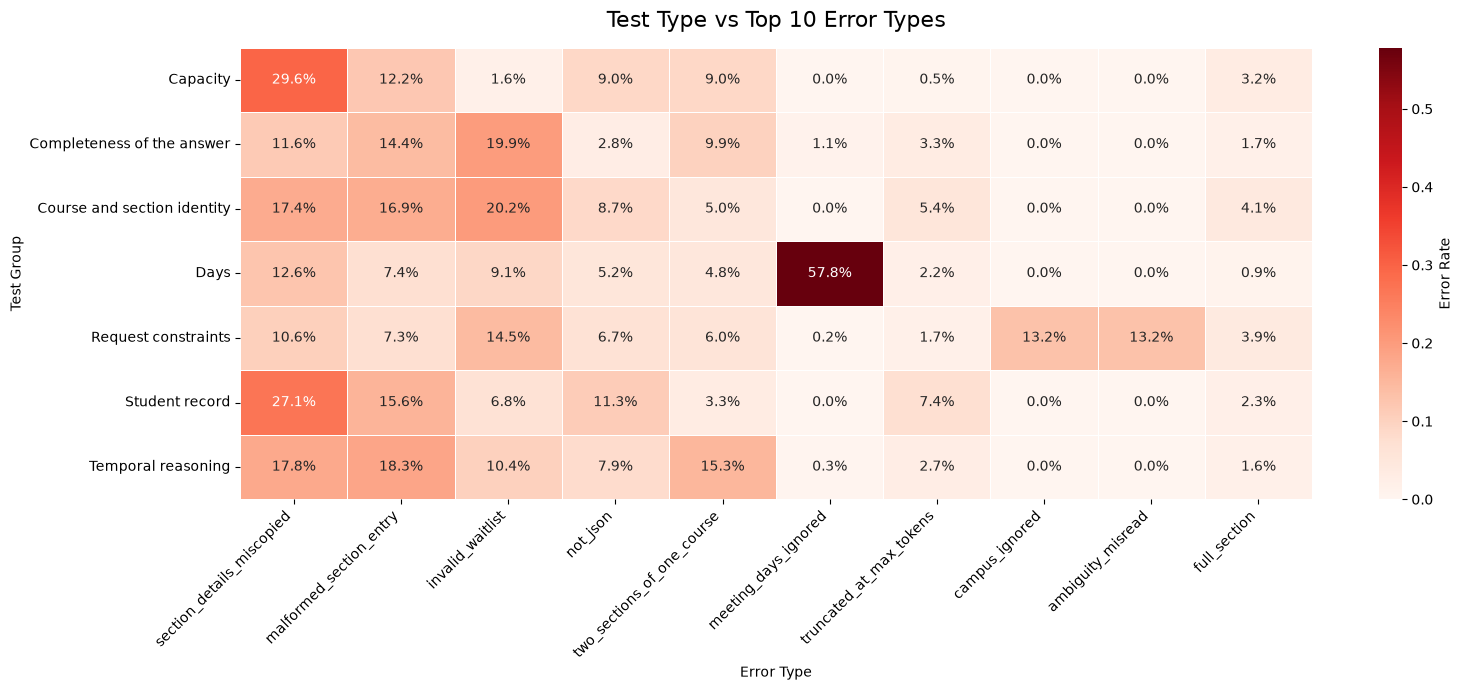

In [27]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    calculate_error_distribution("group"),
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Test Type vs Top 10 Error Types", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Test Group")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Test Group vs Top 10 Error Types Heatmap (Percentage of Errors)

## Purpose of the Heatmap

This heatmap compares the seven test groups against the 10 most frequently occurring error types in the evaluation experiments.

The purpose of this visualization is to investigate how the distribution of errors differs across the different test groups.

It helps us understand which specific errors make up a larger proportion of the errors within each test group and whether certain types of tasks are associated with particular error patterns.

## How to Read the Heatmap

- **Rows:** Each row represents one of the seven test groups.
- **Columns:** Each column represents one of the 10 most frequently occurring error types.
- **Cells:** Each cell displays the percentage of all recorded errors within that test group that belong to the corresponding error type.
- **Color intensity:** Darker red indicates that the error represents a larger proportion of the errors within that test group, while lighter red indicates a smaller proportion.

The percentages allow us to compare the composition of errors across different test groups.

## Understanding the Seven Test Groups

The heatmap includes seven test groups:

1. **Student record:** Evaluates tasks involving student record information.
2. **Temporal reasoning:** Evaluates tasks involving time-related reasoning and scheduling.
3. **Request constraints:** Evaluates whether the model follows specific requirements and restrictions in a request.
4. **Course and section identity:** Evaluates tasks involving correct course and section identification.
5. **Capacity:** Evaluates tasks involving course capacity and availability.
6. **Days:** Evaluates tasks involving meeting days and scheduling requirements.
7. **Completeness of the answer:** Evaluates whether the model provides all the required information in its response.

These groups allow us to examine whether different types of evaluation tasks are associated with different error patterns.

## What This Heatmap Helps Reveal

The visualization helps identify differences in error patterns across the test groups.

For example:

- If the Capacity row has a higher percentage under `invalid_waitlist`, this means invalid waitlist errors make up a larger proportion of the errors in Capacity tasks.
- If the Days row has a higher percentage under `meeting_days_ignored`, this means meeting-day errors account for a larger share of the errors in Days tasks.
- If an error has similar percentages across multiple test groups, that error makes up a similar proportion of the errors in those groups.
- If some errors account for a larger proportion of errors in certain test groups while others account for a smaller proportion, this suggests that different task categories produce different error patterns.

These comparisons help us investigate which types of evaluation tasks are associated with particular mistakes.

## Why Percentages of Errors Are Used Instead of Raw Error Counts

The heatmap uses percentages of total errors rather than raw error counts.

For each test group, the number of occurrences of a particular error type is divided by the total number of recorded errors within that test group.

This allows us to compare the relative distribution of errors across test groups

In [28]:
new_effort_rates = calculate_error_distribution("effort")

# Keep effort levels in the correct order
new_effort_rates = new_effort_rates.reindex(["low", "medium", "high"])

print(new_effort_rates)

error_type  section_details_miscopied  malformed_section_entry  \
effort                                                           
low                          0.165025                 0.129310   
medium                       0.198462                 0.121538   
high                         0.188218                 0.143678   

error_type  invalid_waitlist  not_json  two_sections_of_one_course  \
effort                                                               
low                 0.119458  0.081281                    0.067734   
medium              0.118462  0.073846                    0.058462   
high                0.104885  0.080460                    0.093391   

error_type  meeting_days_ignored  truncated_at_max_tokens  campus_ignored  \
effort                                                                      
low                     0.060345                 0.033251        0.024631   
medium                  0.073846                 0.038462        0.030769   
high      

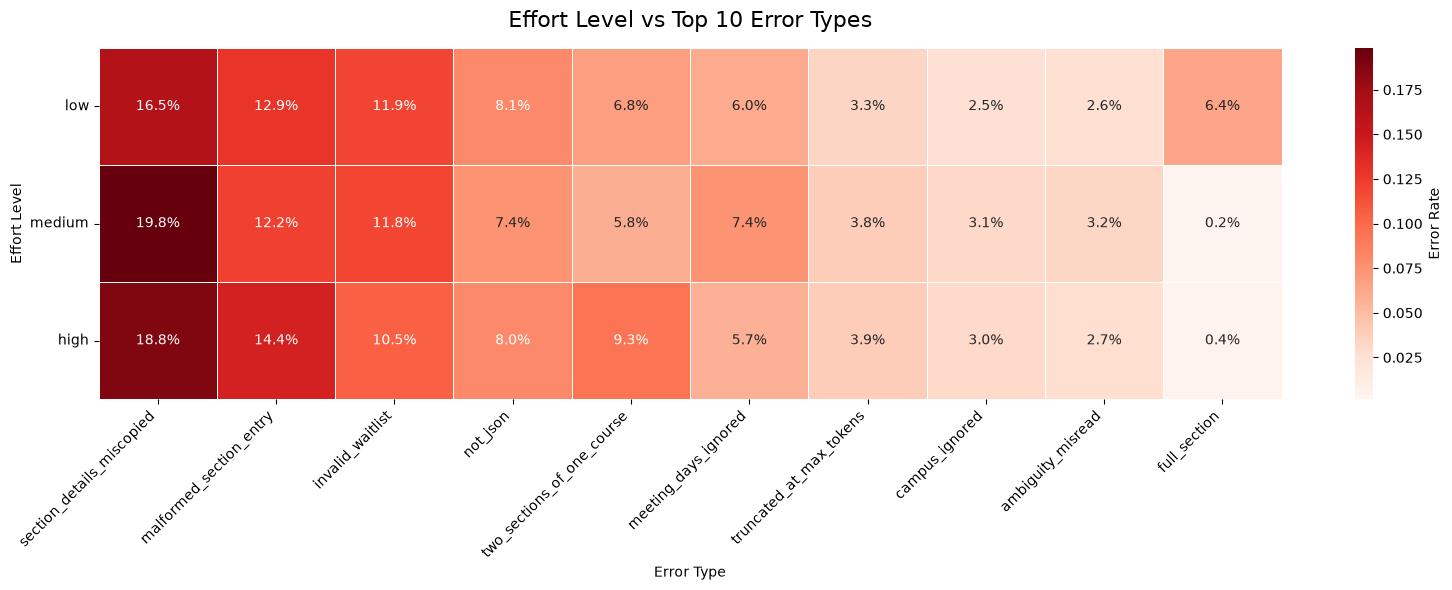

In [29]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    new_effort_rates,
    annot=True,
    fmt=".1%",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Error Rate"}
)

plt.title("Effort Level vs Top 10 Error Types", fontsize=16, pad=15)
plt.xlabel("Error Type")
plt.ylabel("Effort Level")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Effort Level vs Top 10 Error Types Heatmap (Percentage of Errors)

Purpose of the Heatmap

This heatmap compares three different reasoning effort levels (Low, Medium, and High) against the 10 most frequently occurring error types in the evaluation experiments.

The purpose of this visualization is to investigate how the distribution of errors differs across reasoning effort levels.

It helps us understand which specific errors make up a larger proportion of the errors at each effort level and whether different effort levels produce different error patterns.

How to Read the Heatmap

Rows: Each row represents one of the three reasoning effort levels: Low, Medium, and High.

Columns: Each column represents one of the 10 most frequently occurring error types.

Cells: Each cell displays the percentage of all recorded errors at that effort level that belong to the corresponding error type.

Color intensity: Darker red indicates that the error represents a larger proportion of the errors at that effort level, while lighter red indicates a smaller proportion.

The percentages allow us to compare the composition of errors across different reasoning effort levels.

Understanding the Three Effort Levels

The heatmap includes three effort levels:

Low: Represents evaluations conducted using a low reasoning effort setting.

Medium: Represents evaluations conducted using a medium reasoning effort setting.

High: Represents evaluations conducted using a high reasoning effort setting.

These levels allow us to examine whether the distribution of specific error types differs depending on the reasoning effort setting.

What This Heatmap Helps Reveal

The visualization helps identify differences in error patterns across reasoning effort levels.

For example:

If the Low effort row has a higher percentage than the High effort row under not_json, this means that invalid JSON errors make up a larger proportion of Low effort's errors.

If the High effort row has a lower percentage under meeting_days_ignored, this means that meeting-day errors account for a smaller proportion of High effort's errors.

If an error has similar percentages across all three rows, that error makes up a similar proportion of the errors at each effort level.

If some errors account for a larger proportion of errors at one effort level while others account for a smaller proportion, this suggests that the composition of errors differs across effort levels.

These comparisons help us investigate how reasoning effort is associated with the types of mistakes produced by the models.

Why Percentages of Errors Are Used Instead of Raw Error Counts

The heatmap uses percentages of total errors rather than raw error counts.

For each effort level, the number of occurrences of a particular error type is divided by the total number of recorded errors at that effort level.

This allows us to compare the relative distribution of errors across Low, Medium, and High effort, even when the total number of errors differs between effort levels.

For example, if not_json accounts for 20% of Low effort errors and 10% of High effort errors, it means that JSON formatting errors make up a larger share of Low effort's errors.

However, this does not necessarily mean that Low effort produces more JSON formatting errors overall. The total number of errors at each effort level must also be considered.

Important Observations When Interpreting Results

The heatmap should be interpreted by comparing patterns across both rows and columns:

Comparing across a row shows which error types make up larger or smaller proportions of the errors at a particular effort level.

Comparing down a column shows how the proportion of a particular error type changes between Low, Medium, and High effort.

A darker cell indicates that a particular error type accounts for a larger share of errors at that effort level. It does not automatically mean that the effort level produces more errors overall.

The heatmap includes only the 10 most frequently occurring error types across the entire dataset. The remaining 41 error types are not displayed. Therefore, the percentages across the displayed 10 columns will not necessarily add up to 100%.

Additionally, the results are aggregated across all 11 language models and all seven test groups. Differences in the distribution of errors may therefore reflect differences in the models or test groups represented at each effort level, rather than reasoning effort alone.